# HW 1

Для запуска из корня репозитория:

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install -r hw1/requirements.txt
python hw1/scripts/execute_notebook.py
```

Скрипт выполнит ноутбук и сохранит ячейки с результатами. Можно также открыть `hw1/experiments.ipynb` в Jupyter или VS Code и выполнить ячейки из папки `hw1`.

Отзывы и метаданные скачиваются автоматически в `hw1/data/`, если их еще нет. По умолчанию используются сохраненные результаты из `hw1/results/`. Для повторного обучения нужно поставить `RETRAIN = True`. Seed равен 42, параметры подбора приведены ниже.

Использую [Amazon Reviews 2018, Video Games, 5-core](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/). Архивы отзывов и метаданных скачиваются автоматически. `reviewerID` обозначает пользователя, `asin` товар, `overall` оценку от 1 до 5, `unixReviewTime` время отзыва. Один отзыв считаю взаимодействием. Рекомендую еще не оцененные товары, релевантными считаю оценки 4 и 5.

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from data_pipeline import prepare
from experiment import run, grid
from pathlib import Path

SEED = 42
RETRAIN = False
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_colwidth', 120)

В исходных данных 497 577 отзывов, пропусков и некорректных записей нет. Для повторных пар пользователь-товар оставляю первый отзыв, чтобы не учитывать одну пару несколько раз. После удаления 24 150 повторов остается 473 427 взаимодействий.

После временного разбиения выбираю по train 5 000 популярных товаров и пользователей с минимум пятью обучающими взаимодействиями на них. Это уменьшает матрицы и оставляет достаточно истории для обучения. В итоге получаю 219 626 взаимодействий, 24 306 пользователей и 5 000 товаров. Такой отбор смещает выборку к активным пользователям и популярным товарам.

In [2]:
raw, selected, train, validation, test, metadata, info = prepare()
shape = (info['users'], info['items'])
display(pd.Series({key: value for key, value in info.items() if not isinstance(value, (dict, list))}, name='Значение').to_frame())
display(pd.Series(info['missing'], name='Пропуски исходных полей').to_frame())

,Значение
raw_rows,4.975770e+05
invalid_rows,0.000000e+00
duplicate_pairs,2.415000e+04
clean_rows,4.734270e+05
selected_rows,2.196260e+05
users,2.430600e+04
items,5.000000e+03
train_rows,2.113260e+05
validation_rows,4.788000e+03
test_rows,3.512000e+03


,Пропуски исходных полей
user_id,0
item_id,0
rating,0
timestamp,0


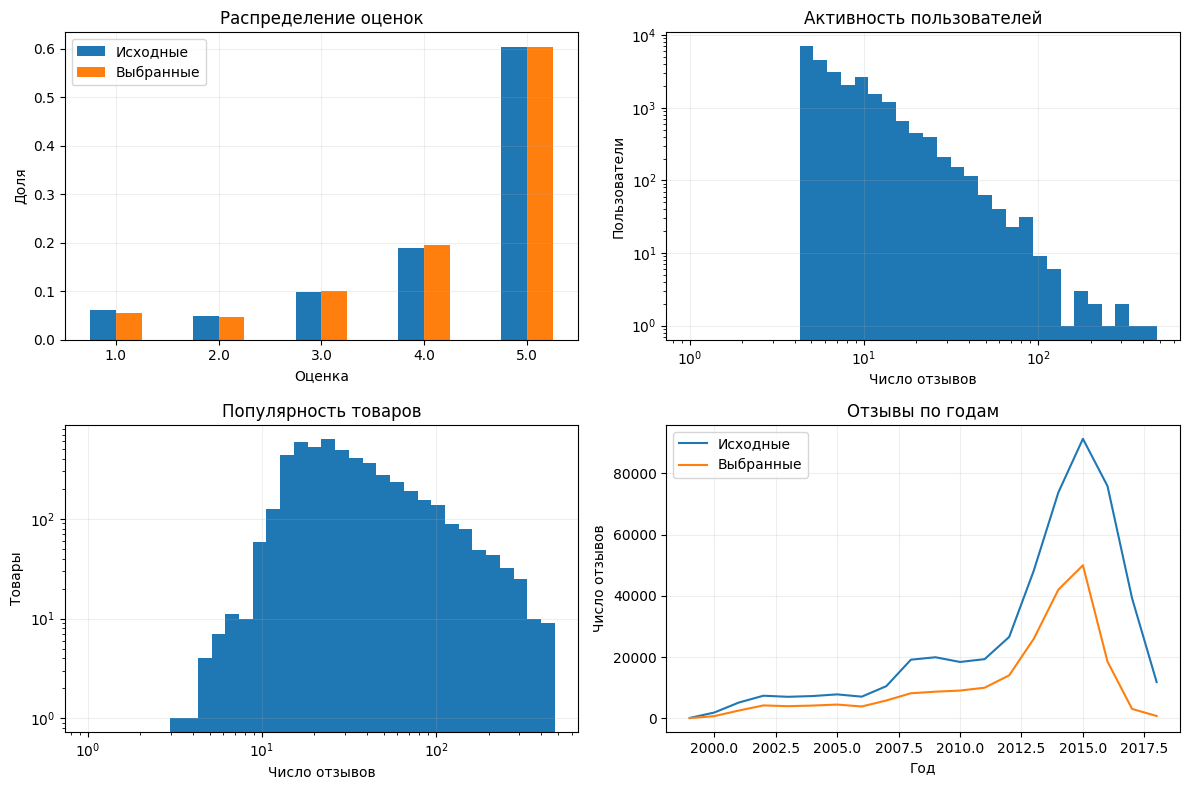

,Активность,Популярность
count,24306.000000,5000.000000
mean,9.035876,43.925200
std,9.249471,48.769984
min,5.000000,3.000000
25%,5.000000,19.000000
50%,7.000000,27.000000
75%,9.000000,47.000000
max,478.000000,480.000000


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ratings = pd.concat([raw.rating.value_counts(normalize=True).rename('Исходные'), selected.rating.value_counts(normalize=True).rename('Выбранные')], axis=1).sort_index()
ratings.plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title='Распределение оценок', xlabel='Оценка', ylabel='Доля')
axes[0, 1].hist(selected.groupby('user').size(), bins=np.geomspace(1, selected.groupby('user').size().max()+1, 35))
axes[0, 1].set(xscale='log', yscale='log', title='Активность пользователей', xlabel='Число отзывов', ylabel='Пользователи')
axes[1, 0].hist(selected.groupby('item').size(), bins=np.geomspace(1, selected.groupby('item').size().max()+1, 35))
axes[1, 0].set(xscale='log', yscale='log', title='Популярность товаров', xlabel='Число отзывов', ylabel='Товары')
for frame, label in [(raw, 'Исходные'), (selected, 'Выбранные')]:
    pd.to_datetime(frame.timestamp, unit='s', utc=True).dt.year.value_counts().sort_index().plot(ax=axes[1, 1], label=label)
axes[1, 1].set(title='Отзывы по годам', xlabel='Год', ylabel='Число отзывов')
axes[1, 1].legend()
fig.tight_layout()
plt.show()
display(selected.groupby('user').size().describe().rename('Активность').to_frame().join(selected.groupby('item').size().describe().rename('Популярность')))

,Доля непустых полей каталога
title,0.9986
category,0.9948
description,0.9828
brand,0.9958


Пустых категорий после удаления HTML: 4268


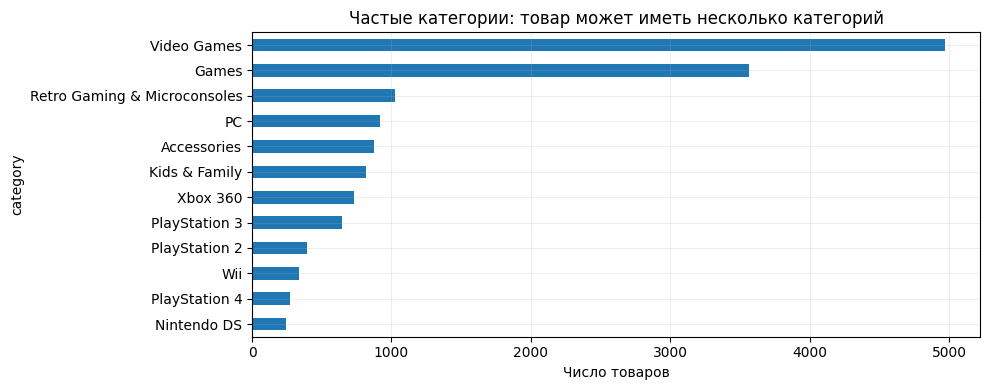

,title,category
asin,,
0700099867,Dirt 3,"[Video Games, PC, Games]"
0804161380,Legend of Zelda Box Set Prima Official Game Guide,[]
6050036071,"USB Microphone for RockBand or Guitar Hero (PS3, Wii, Xbox360)","[Video Games, PlayStation 3, Accessories, Controllers, Music Controllers, Microphones, </span></span></span>]"
9625990674,Silicone Protective Case for Controller (Black),"[Video Games, Xbox 360, Accessories]"
9629971372,Dotop Sony Playstation 2 PS2 64MB Memory Card,"[Video Games, Retro Gaming &amp; Microconsoles, PlayStation 2, Accessories]"


In [4]:
display(pd.Series(info['metadata_coverage'], name='Доля непустых полей каталога').to_frame())
import html
import re
raw_categories = metadata.category.dropna().explode().dropna().astype(str)
clean_categories = raw_categories.map(lambda value: html.unescape(re.sub(r'<[^>]+>', '', value)).strip())
print('Пустых категорий после удаления HTML:', int(clean_categories.eq('').sum()))
category_counts = clean_categories[clean_categories.ne('')].value_counts().head(12)
category_counts.sort_values().plot.barh(title='Частые категории: товар может иметь несколько категорий', xlabel='Число товаров')
plt.tight_layout()
plt.show()
display(metadata[['title', 'category']].head(5))

Около 60% оценок пятерки

Разреженность составляет 99,82%. Медиана числа отзывов у пользователя равна 7, у товара 27. Названия и категории заполнены более чем у 99% товаров. Дубли метаданных убираю по ASIN, для графика категорий удаляю HTML-теги.

Каталог выбираю только по train, новых пользователей и товары исключаю.
Для всех моделей использую одних пользователей и весь каталог, уже оцененные товары убираю из рекомендаций. При равных предиктах сортирую по ASIN.
Выбираю параметры по NDCG@10, которая учитывает порядок рекомендаций, и дополнительно считаю Recall@10
После подбора обучаю модели на train + validation и сравниваю на test.

In [5]:
boundaries = pd.to_datetime([info['first_cutoff'], info['second_cutoff']], unit='s', utc=True)
print('Начало validation:', boundaries[0], '| Начало test:', boundaries[1])
display(pd.DataFrame(info['exclusions']).set_index('period'))
periods = pd.DataFrame([
    {'Период': name, 'Взаимодействия': len(frame), 'Пользователи': frame.user.nunique(), 'Товары': frame.item.nunique()}
    for name, frame in [('train', train), ('validation', validation), ('test', test)]
])
display(periods)

Начало validation: 2016-05-05 00:00:00+00:00 | Начало test: 2017-01-15 00:00:00+00:00


,raw_interactions,new_user_interactions,new_users,new_item_interactions,new_items,excluded_total,retained_interactions
period,,,,,,,
validation,47407,16311,2948,9672,630,42619,4788
test,47368,20096,3525,11526,747,43856,3512


,Период,Взаимодействия,Пользователи,Товары
0,train,211326,24306,5000
1,validation,4788,2312,1949
2,test,3512,1842,1638


Код моделей находится в `models/`. Здесь $X_{ui}=1$, если оценка не ниже 4, иначе 0.

**ItemCF.** Считаю косинусное сходство товаров и оставляю $k$ соседей:
$$s_{ij}=\frac{X_{:i}^{T}X_{:j}}{\|X_{:i}\|\|X_{:j}\|},\quad s_{ii}=0,\qquad \hat y_{ui}=\sum_jX_{uj}s_{ji}.$$

**iALS.** По очереди обновляю факторы пользователей и товаров:
$$\min_{A,B}\sum_{u,i}c_{ui}(X_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2).$$
Для известных пар $c_{ui}=1+\alpha$, для остальных - 1.

**EASE.** Обучаю линейную модель с нулевой диагональю:
$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\quad W_{ii}=0.$$
Для $P=(X^TX+\lambda I)^{-1}$ получаю $W_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$. Предсказания - $XW$.

**FM.** Использую ID пользователя и товара. Добавляю для каждого $\log(1+n)$, среднюю оценку / 5 и долю положительных отзывов. Это признаки активности и оценок. Считаю их только по прошлой истории.
$$\hat y(x)=w_0+\sum_jw_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.$$
Обучаю с BCE и Adam. На каждый отзыв добавляю один случайный еще не оцененный товар с меткой 0. `FM_ID` - вариант без дополнительных признаков.

**CustomALS.** Меняю только таргет iALS:
$$t_{ui}=\max(r_{ui}-3,0)/2.$$
Оценка 4 дает 0,5, оценка 5 - 1. Проверяю, помогает ли различать четверки и пятерки. При оценке качества четверки и пятерки по-прежнему одинаково положительные.

Фиксирую seed 42. Перебираю настройки из таблицы ниже и выбираю лучшие по NDCG@10 на validation.

Для ALS использую 15 итераций, а для FM до 20 эпох с остановкой после трех эпох без улучшения. При переобучении FM беру лучшую эпоху с validation.

In [6]:
search_space = pd.DataFrame([{'Модель': name, 'Параметры': params} for name, params in grid()])
display(search_space)

,Модель,Параметры
0,ItemCF,{'neighbors': 50}
1,ItemCF,{'neighbors': 100}
2,ItemCF,{'neighbors': 200}
3,EASE,{'reg': 10}
4,EASE,{'reg': 100}
5,EASE,{'reg': 1000}
6,iALS,"{'factors': 32, 'reg': 0.1, 'alpha': 10, 'iterations': 15}"
7,iALS,"{'factors': 32, 'reg': 0.1, 'alpha': 40, 'iterations': 15}"
8,iALS,"{'factors': 32, 'reg': 1.0, 'alpha': 10, 'iterations': 15}"
9,iALS,"{'factors': 32, 'reg': 1.0, 'alpha': 40, 'iterations': 15}"


In [7]:
result_path = Path('results/experiment.json')
if RETRAIN or not result_path.exists():
    results = run()
else:
    results = json.loads(result_path.read_text())
print('Пользователей validation:', results['validation_users'], '| test:', results['test_users'])
validation_results = pd.DataFrame([{k: v for k, v in row.items() if k != 'history'} for row in results['validation']])
display(validation_results.sort_values(['model', 'NDCG@10'], ascending=[True, False]).reset_index(drop=True))

Пользователей validation: 1894 | test: 1491


,model,params,fit_seconds,NDCG@10,Recall@10,best_epoch
0,CustomALS,"{'factors': 64, 'reg': 1.0, 'alpha': 10, 'iterations': 15}",23.389495,0.031785,0.052063,NaN
1,CustomALS,"{'factors': 64, 'reg': 0.1, 'alpha': 10, 'iterations': 15}",23.035117,0.031775,0.052139,NaN
2,CustomALS,"{'factors': 64, 'reg': 0.1, 'alpha': 40, 'iterations': 15}",21.688029,0.030143,0.050211,NaN
3,CustomALS,"{'factors': 64, 'reg': 1.0, 'alpha': 40, 'iterations': 15}",22.183638,0.029634,0.049213,NaN
4,CustomALS,"{'factors': 32, 'reg': 0.1, 'alpha': 10, 'iterations': 15}",11.066915,0.029555,0.047491,NaN
5,CustomALS,"{'factors': 32, 'reg': 1.0, 'alpha': 10, 'iterations': 15}",11.028374,0.029346,0.047030,NaN
6,CustomALS,"{'factors': 32, 'reg': 1.0, 'alpha': 40, 'iterations': 15}",11.065341,0.026747,0.045025,NaN
7,CustomALS,"{'factors': 32, 'reg': 0.1, 'alpha': 40, 'iterations': 15}",10.983982,0.026179,0.044771,NaN
8,EASE,{'reg': 100},6.828493,0.033111,0.053582,NaN
9,EASE,{'reg': 1000},6.619716,0.031136,0.051349,NaN


,Модель,Параметры,Лучшая эпоха,NDCG@10,Recall@10
0,ItemCF,{'neighbors': 200},NaN,0.026912,0.043933
1,EASE,{'reg': 100},NaN,0.033111,0.053582
2,iALS,"{'factors': 64, 'reg': 0.1, 'alpha': 10, 'iterations': 15}",NaN,0.032720,0.052742
3,CustomALS,"{'factors': 64, 'reg': 1.0, 'alpha': 10, 'iterations': 15}",NaN,0.031785,0.052063
4,FM,"{'factors': 32, 'reg': 0.0001, 'metadata': True, 'epochs': 20}",15.0,0.028129,0.043398
5,FM_ID,"{'factors': 16, 'reg': 1e-05, 'metadata': False, 'epochs': 20}",19.0,0.017286,0.027623


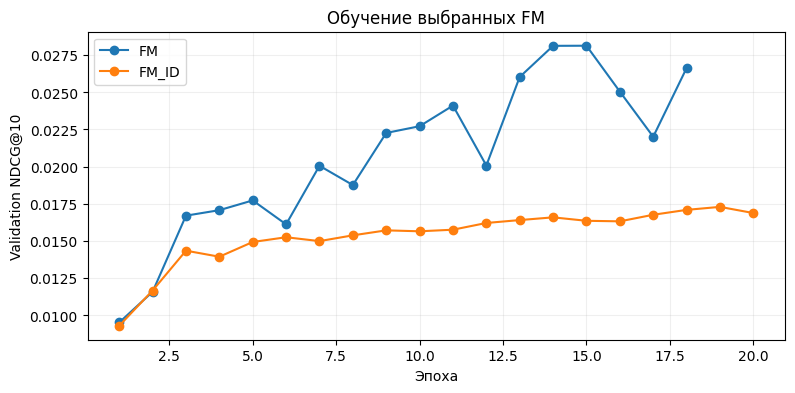

In [8]:
selected_results = pd.DataFrame([{'Модель': name, 'Параметры': row['params'], 'Лучшая эпоха': row.get('best_epoch'), 'NDCG@10': row['NDCG@10'], 'Recall@10': row['Recall@10']} for name, row in results['selected'].items()])
display(selected_results)
fig, ax = plt.subplots(figsize=(9, 4))
for name in ['FM', 'FM_ID']:
    curve = pd.DataFrame(results['selected'][name]['history'])
    ax.plot(curve.epoch, curve.ndcg, marker='o', label=name)
ax.set(xlabel='Эпоха', ylabel='Validation NDCG@10', title='Обучение выбранных FM')
ax.legend()
plt.show()

Сравниваю модели на test. Время обучения указано в секундах, для FM оно включает подготовку примеров при первом запуске.

,params,fit_seconds,NDCG@10,Recall@10
model,,,,
CustomALS,"{'factors': 64, 'reg': 1.0, 'alpha': 10, 'iterations': 15}",22.725351,0.028529,0.050948
EASE,{'reg': 100},8.638859,0.027801,0.051489
iALS,"{'factors': 64, 'reg': 0.1, 'alpha': 10, 'iterations': 15}",23.007122,0.025403,0.045463
ItemCF,{'neighbors': 200},0.991785,0.022411,0.042861
FM,"{'factors': 32, 'reg': 0.0001, 'metadata': True, 'epochs': 15}",57.465676,0.019621,0.038132


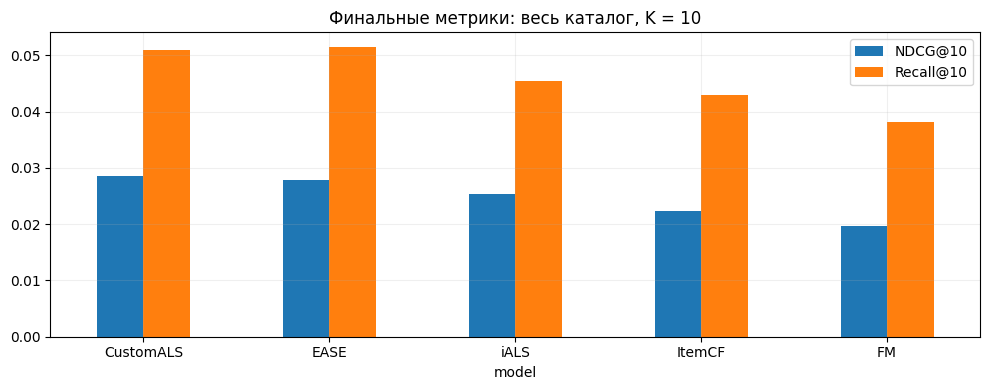

,params,fit_seconds,NDCG@10,Recall@10
model,,,,
FM,"{'factors': 32, 'reg': 0.0001, 'metadata': True, 'epochs': 15}",57.465676,0.019621,0.038132
FM_ID,"{'factors': 16, 'reg': 1e-05, 'metadata': False, 'epochs': 19}",7.425177,0.015663,0.029620
FM_ID_matched,"{'factors': 32, 'reg': 0.0001, 'metadata': False, 'epochs': 15}",8.068991,0.009708,0.019057
iALS,"{'factors': 64, 'reg': 0.1, 'alpha': 10, 'iterations': 15}",23.007122,0.025403,0.045463
CustomALS,"{'factors': 64, 'reg': 1.0, 'alpha': 10, 'iterations': 15}",22.725351,0.028529,0.050948
CustomALS_matched,"{'factors': 64, 'reg': 0.1, 'alpha': 10, 'iterations': 15}",22.387970,0.028664,0.050948


In [9]:
final = pd.DataFrame(results['test']).set_index('model')
main_names = ['ItemCF', 'iALS', 'EASE', 'FM', 'CustomALS']
main = final.loc[main_names].sort_values('NDCG@10', ascending=False)
display(main)
main[['NDCG@10', 'Recall@10']].plot.bar(rot=0, title='Финальные метрики: весь каталог, K = 10')
plt.tight_layout()
plt.show()
display(final.loc[['FM', 'FM_ID', 'FM_ID_matched', 'iALS', 'CustomALS', 'CustomALS_matched']])

In [10]:
# Пример рекомендаций EASE.
item_ids = sorted(selected.item_id.unique())
example_items = results['recommendations']['EASE'][0]
example = metadata.loc[[item_ids[i] for i in example_items], ['title', 'category']].copy()
example.insert(0, 'Место', np.arange(1, 11))
example.index.name = 'ASIN'
print('Пользователь:', results['example_users'][0])
display(example)

Пользователь: 1


,Место,title,category
ASIN,,,
B0050SX1JO,1,Sports Champions 2 - Playstation 3,"[Video Games, Kids & Family, PlayStation 3, Games, </span></span></span>]"
B0050SXQ12,2,PS3 Everybody Dance,"[Video Games, PlayStation 3, Games, </span></span></span>]"
B00D7TYIY0,3,Just Dance 2014 - Playstation 3,"[Video Games, Kids & Family, PlayStation 3, Games, </span></span></span>]"
B004X56PWK,4,Sonic Generations - PlayStation 3,"[Video Games, Kids & Family, PlayStation 3, Games, </span></span></span>]"
B002I0J8KS,5,The Fight,"[Video Games, PlayStation 3, Games, </span></span></span>]"
B0072HYRNK,6,Sony PlayStation 3 Move Motion Controller (Bulk Packaging),"[Video Games, PlayStation 3, Accessories, Controllers, </span></span></span>]"
B00KTNSKT6,7,Just Dance 2015 - PlayStation 3,"[Video Games, Kids & Family, PlayStation 3, Games, </span></span></span>]"
B00A750QIE,8,MLB 13 The Show - Playstation 3,"[Video Games, Kids & Family, PlayStation Vita, Games, </span></span></span>]"
B003VUO6H4,9,Sony Playstation 3 160GB System,"[Video Games, PlayStation 3, </span></span></span>]"


### Выводы

По NDCG@10 лучше всего получился CustomALS с результатом 0,02853 при 64 факторах, регуляризации 1 и alpha 10. По Recall@10 немного лучше EASE с регуляризацией 100, у нее 0,05149.

Новый таргет ALS помог: при одинаковых настройках NDCG@10 вырос с 0,02540 до 0,02866. Дополнительные признаки FM тоже улучшили результат с 0,00971 до 0,01962, но до остальных моделей FM не дотянула.

После отбора на test остался 1 491 пользователь, поэтому результаты относятся только к активным пользователям и популярным товарам. На другом разбиении порядок моделей может измениться.